# 13. Cobertura e extrapolação: adaptação didática de ideias do `stressor`

O manual do pacote R `stressor` descreve `cv_cluster` (validação por grupos de características), `dist_cent` (distância ao centro da população) e `thinning` (redução do conjunto de treino e nova estimação). Aqui traduzimos **as perguntas** para Python e para o Booster final **congelado**, com uma distinção importante: a análise de janelas pequenas abaixo **não é** o algoritmo original `thinning`, que retreina a cada redução. O manual do pacote R `stressor`, identificado na bibliografia do relatório, é a fonte metodológica dessa inspiração.

**Perguntas:** O desempenho do modelo muda em regiões menos cobertas pelo treino? Se aumentar a proporção dessas regiões, quanto drift aparece e como variam AUC ROC, PR-AUC trapezoidal, KS e Brier? Uma janela pequena pode produzir PSI ou métricas aparentemente extremos mesmo sem mudança populacional?

Usamos o mesmo `scale_pos_weight=13.882494684620836`, threshold **0,50** e holdout rotulado da nova suíte. Clusters, transformação e quantis de distância são **ajustados só em `Xt`**. Nenhum rótulo entra no ajuste da distância. O Booster não é reestimado.

## Roteiro

1. Reconstruir splits e referência.
2. Formar representação robusta de perfis e clusters usando apenas o treino.
3. Avaliar o holdout por cluster e por distância ao centro mais próximo.
4. Aumentar gradualmente o peso dos perfis distantes e medir ESS, drift e desempenho.
5. Repetir amostras pequenas da mesma população para estimar a variabilidade de métricas e PSI.


In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


## 13.1 Referência rotulada e modelo congelado

O CSV `cs-test.csv` continua sem rótulos e não entra nas métricas de performance. O split de 15% e o segundo split de validação reproduzem `model_final.ipynb`; o manifesto e SHA-256 protegem a versão do Booster. A inferência usa todas as árvores armazenadas, como no notebook de origem.


In [2]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_curve, auc)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
SEMENTE = 33
CORTE = 0.50
PESO_POSITIVO = 13.882494684620836
P = DATA_DIR_PROJECT
RAIZ = next((d for d in [P, P.parent] if (d / "cs-training.csv").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Execute a partir da raiz do projeto ou de notebooks/.")
SAIDA = TABLES_DIR
SAIDA.mkdir(exist_ok=True)
MANIFESTO = json.loads((MODEL_DIR / 'manifesto_modelo.json').read_text(encoding="utf-8"))
ARQUIVO_MODELO = MODEL_DIR / 'model_class_retreinado.json'
assert abs(MANIFESTO["params_fornecidos"]["scale_pos_weight"] - PESO_POSITIVO) < 1e-12
assert MANIFESTO["cutoff"] == CORTE
assert hashlib.sha256(ARQUIVO_MODELO.read_bytes()).hexdigest() == MANIFESTO["model_sha256"]
FEATURES = MANIFESTO["features"]
ALVO = MANIFESTO["target"]
bruto = pd.read_csv(RAIZ / "cs-training.csv").drop(columns="Unnamed: 0")
assert list(bruto.drop(columns=ALVO).columns) == FEATURES
Xtv, Xh, ytv, yh = train_test_split(bruto[FEATURES], bruto[ALVO].astype(int),
                                    test_size=0.15, random_state=SEMENTE)
Xt, Xv, yt, yv = train_test_split(Xtv, ytv, test_size=0.1765, random_state=SEMENTE)
assert (len(Xt), len(Xv), len(Xh)) == (104996, 22504, 22500)
y = yh.to_numpy(dtype=int)
modelo = xgb.Booster()
modelo.load_model(str(ARQUIVO_MODELO))
assert modelo.feature_names is None or modelo.feature_names == FEATURES
modelo.set_param({"device": "cpu", "nthread": 4})  # Só a inferência vai para CPU.
assert modelo.num_boosted_rounds() == MANIFESTO["num_boosted_rounds"]
def predizer(X):
    return modelo.predict(xgb.DMatrix(X[FEATURES], feature_names=FEATURES)).astype(float)
p0 = predizer(Xh)
print("Treino:", len(Xt), "| validação:", len(Xv), "| holdout:", len(Xh))
print("Peso positivo:", PESO_POSITIVO, "| corte:", CORTE,
      "| árvores armazenadas:", modelo.num_boosted_rounds())

Treino: 104996 | validação: 22504 | holdout: 22500
Peso positivo: 13.882494684620836 | corte: 0.5 | árvores armazenadas: 103


## 13.2 Métricas e símbolos

As quatro métricas centrais são AUC ROC, PR-AUC **trapezoidal**, KS do modelo e Brier, definidas no notebook 12. AP é mostrada separadamente e não equivale à PR-AUC trapezoidal. Recall e precisão em 0,50 são referências descritivas, sem critério de parada. O KS do modelo usa rótulos e scores; não se confunde com PSI nem com KS entre distribuições de entradas.

Para pesos positivos `w_i`, o tamanho efetivo da amostra é `ESS = (Σ_i w_i)² / Σ_i w_i²`; `ESS/n` perto de 1 indica concentração pequena de pesos. Aqui `p_i` é o score congelado e `y_i` o rótulo verdadeiro do holdout. As métricas ponderadas descrevem uma **população hipotética formada por linhas reais**. Essa leitura depende da hipótese de que a relação `P(Y|X)` permanece aplicável nesse rearranjo e de que há suporte suficiente; aumentar peso de perfis já vistos não descobre o comportamento do modelo em regiões nunca observadas.

`AP_lift = AP/prevalência` compara a AP à referência de um ranking aleatório na mesma prevalência. É uma razão **descritiva**, dependente do mix. Tanto AP quanto PR-AUC podem subir quando há mais positivos, mesmo se AUC, KS ou Brier piorarem; por isso relatamos prevalência e as quatro métricas em conjunto. Nenhum valor encerra a grade de estresse.


In [3]:
def metricas(y, p, pesos=None):
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)
    w = np.ones(len(y), dtype=float) if pesos is None else np.asarray(pesos, dtype=float)
    if not (len(y) == len(p) == len(w)) or not np.isfinite(w).all() or (w < 0).any() or w.sum() <= 0:
        raise ValueError("Rótulos, escores ou pesos inválidos.")
    classe = p >= CORTE
    tp = w[(y == 1) & classe].sum()
    fn = w[(y == 1) & ~classe].sum()
    fp = w[(y == 0) & classe].sum()
    tn = w[(y == 0) & ~classe].sum()
    prev = np.average(y, weights=w)
    if np.unique(y[w > 0]).size < 2:
        raise ValueError("AUC ROC, PR-AUC e KS exigem as duas classes com peso positivo.")
    precision_curve, recall_curve, _ = precision_recall_curve(y, p, sample_weight=w)
    fpr_curve, tpr_curve, _ = roc_curve(y, p, sample_weight=w, drop_intermediate=False)
    ap = average_precision_score(y, p, sample_weight=w)
    return {
        "auc_roc": roc_auc_score(y, p, sample_weight=w),
        "pr_auc_trap": auc(recall_curve, precision_curve),
        "ks_modelo": float(np.max(tpr_curve - fpr_curve)),
        "ap": ap,
        "ap_lift": ap / prev,
        "brier": brier_score_loss(y, p, sample_weight=w),
        "recall": tp / (tp + fn),
        "fpr": fp / (fp + tn),
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "prevalencia": prev,
        "score_medio": np.average(p, weights=w),
        "taxa_alerta": np.average(classe, weights=w),
        "ess": w.sum() ** 2 / np.square(w).sum(),
        "ess_frac": w.sum() ** 2 / np.square(w).sum() / len(w),
    }

def bins_referencia(ref, n_quant=10):
    a = np.asarray(ref, dtype=float)
    a = a[np.isfinite(a)]
    if len(a) == 0:
        return np.array([-np.inf, np.inf])
    internos = np.unique(np.quantile(a, np.linspace(0, 1, n_quant + 1)[1:-1]))
    return np.r_[-np.inf, internos, np.inf]

def contagens(x, arestas, pesos=None):
    a = np.asarray(x, dtype=float)
    w = np.ones(len(a)) if pesos is None else np.asarray(pesos, dtype=float)
    faltante = ~np.isfinite(a)
    cod = np.searchsorted(arestas, a[~faltante], side="right") - 1
    cod = np.clip(cod, 0, len(arestas) - 2)
    bins = np.bincount(cod, weights=w[~faltante], minlength=len(arestas)-1)
    return np.r_[bins, w[faltante].sum()]

def psi(ref, atual, arestas=None, pesos=None, epsilon=1e-6):
    """PSI descritivo, com bins fixos e bin separado para ausência/infinitos."""
    if arestas is None:
        arestas = bins_referencia(ref)
    r = contagens(ref, arestas)
    q = contagens(atual, arestas, pesos)
    r = r / r.sum()
    q = q / q.sum()
    return float(np.sum((q-r) * np.log((q+epsilon)/(r+epsilon))))

base = metricas(y, p0)
for chave, chave_manifesto in [("auc_roc", "auc_roc"), ("pr_auc_trap", "pr_auc_trap"),
                              ("ks_modelo", "ks_modelo"), ("ap", "ap"), ("brier", "brier")]:
    assert np.isclose(base[chave], MANIFESTO["baseline_holdout"][chave_manifesto], atol=1e-6, rtol=0), chave
display(pd.DataFrame([base], index=["Holdout sem estresse"]).round(4))

,auc_roc,pr_auc_trap,ks_modelo,ap,ap_lift,brier,recall,fpr,precision,prevalencia,score_medio,taxa_alerta,ess,ess_frac
Holdout sem estresse,0.8668,0.396,0.5877,0.3964,5.9458,0.144,0.794,0.2068,0.2153,0.0667,0.324,0.2459,22500.0,1.0


## 13.3 Distância e clusters ajustados no treino

Cada variável é preenchida com a mediana do **treino** apenas para calcular vizinhança; o XGBoost continua recebendo as entradas originais, inclusive `NaN`. Valores extremos são limitados para esta representação nos quantis 0,5% e 99,5% do treino. Um `QuantileTransformer` transforma cada coluna por sua posição na distribuição do treino para escala aproximadamente normal; limitamos a saída a `[-3,3]` e acrescentamos indicadores de ausência. Isso evita que a grande escala de `MonthlyIncome` ou `DebtRatio` domine a distância. A escolha é uma definição operacional de similaridade, e deve ser testada com conhecimento de domínio.

O `MiniBatchKMeans` encontra `K=8` centros `μ_k` nos perfis de treino. Para uma linha transformada `z_i`, definimos `d_i = min_k ||z_i − μ_k||₂`, a menor distância euclidiana. Distância grande **sugere** extrapolação relativamente ao treino sob esta representação; não prova que o mutuário seja impossível ou que o modelo vá errar. Bins de distância e o limite de cauda de 95% vêm só do treino.

`cv_cluster` no `stressor` treina modelos deixando clusters de fora. Aqui **não** fazemos isso, porque a pergunta é sobre o Booster final fixo. Mostramos seu desempenho em cada cluster e sua sensibilidade à mistura dos clusters.


In [4]:
from sklearn.preprocessing import QuantileTransformer
from sklearn.cluster import MiniBatchKMeans
from scipy.spatial.distance import cdist

mediana = Xt[FEATURES].median()
q005 = Xt[FEATURES].quantile(.005)
q995 = Xt[FEATURES].quantile(.995)

def preparar_distancia(X):
    faltas = X[FEATURES].isna().to_numpy(dtype=float)
    Ximp = X[FEATURES].fillna(mediana).clip(lower=q005, upper=q995, axis=1)
    Z = np.clip(transformador.transform(Ximp), -3, 3)
    return np.c_[Z, faltas]

transformador = QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEMENTE)
transformador.fit(Xt[FEATURES].fillna(mediana).clip(lower=q005, upper=q995, axis=1))
Zt = preparar_distancia(Xt)
Zh = preparar_distancia(Xh)
K = 8
clusterizador = MiniBatchKMeans(n_clusters=K, random_state=SEMENTE, batch_size=4096, n_init=10)
clusterizador.fit(Zt)
cluster_t = clusterizador.predict(Zt)
cluster_h = clusterizador.predict(Zh)
dist_t = cdist(Zt, clusterizador.cluster_centers_).min(axis=1)
dist_h = cdist(Zh, clusterizador.cluster_centers_).min(axis=1)
assert np.isfinite(dist_h).all() and len(np.unique(cluster_h)) == K
limite95 = np.quantile(dist_t, .95)
print("K:", K, "| distância p95 treino:", round(limite95, 3),
      "| holdout acima desse limite:", f"{np.mean(dist_h > limite95):.1%}")

K: 8 | distância p95 treino: 5.168 | holdout acima desse limite: 5.2%


## 13.4 Desempenho por região do espaço de entrada

Uma métrica de cluster pode oscilar se houver poucos positivos; por isso mostramos `n`, número de positivos e prevalência ao lado das quatro métricas centrais e dos referenciais em 0,50. Os quintis são de **distância no treino**, de modo que o holdout pode ter proporções diferentes. Os clusters não são segmentos de negócio e seus números não têm ordem natural.


,cluster,n,positivos,distancia_media,prevalencia,auc_roc,pr_auc_trap,ks_modelo,brier,ap,recall,precision
0,0,5221,185,2.1068,0.0354,0.7947,0.1606,0.4672,0.1058,0.1632,0.5459,0.1397
1,1,2845,26,2.3232,0.0091,0.7688,0.1259,0.5087,0.0289,0.1296,0.1923,0.1220
2,2,2838,69,2.0631,0.0243,0.7557,0.1268,0.3954,0.0773,0.1314,0.3913,0.1038
3,3,2600,333,3.5241,0.1281,0.7354,0.3047,0.3466,0.3355,0.3074,0.8979,0.1725
4,4,2494,209,2.6876,0.0838,0.8092,0.2681,0.4850,0.2061,0.2720,0.8278,0.1749
5,5,1931,118,2.5180,0.0611,0.8373,0.2952,0.5492,0.1597,0.2996,0.7712,0.1714
6,6,3621,107,1.9333,0.0295,0.7752,0.1390,0.4472,0.0791,0.1429,0.3925,0.1373
7,7,950,453,5.0809,0.4768,0.6525,0.6159,0.2461,0.4271,0.6169,1.0000,0.4768


,quintil_treino,n,positivos,distancia_media,prevalencia,auc_roc,pr_auc_trap,ks_modelo,brier,ap,recall,precision
0,1,4445,69,1.2212,0.0155,0.6787,0.0367,0.3266,0.0564,0.0394,0.1449,0.0769
1,2,4500,111,1.7035,0.0247,0.7807,0.0761,0.4571,0.0797,0.0780,0.3874,0.1044
2,3,4501,140,2.1312,0.0311,0.7781,0.1118,0.4781,0.1050,0.1144,0.4571,0.0941
3,4,4425,252,2.7983,0.0569,0.7966,0.2334,0.4620,0.1627,0.2357,0.7063,0.1409
4,5,4629,928,4.5259,0.2005,0.8163,0.5062,0.4862,0.3110,0.5068,0.9655,0.2940


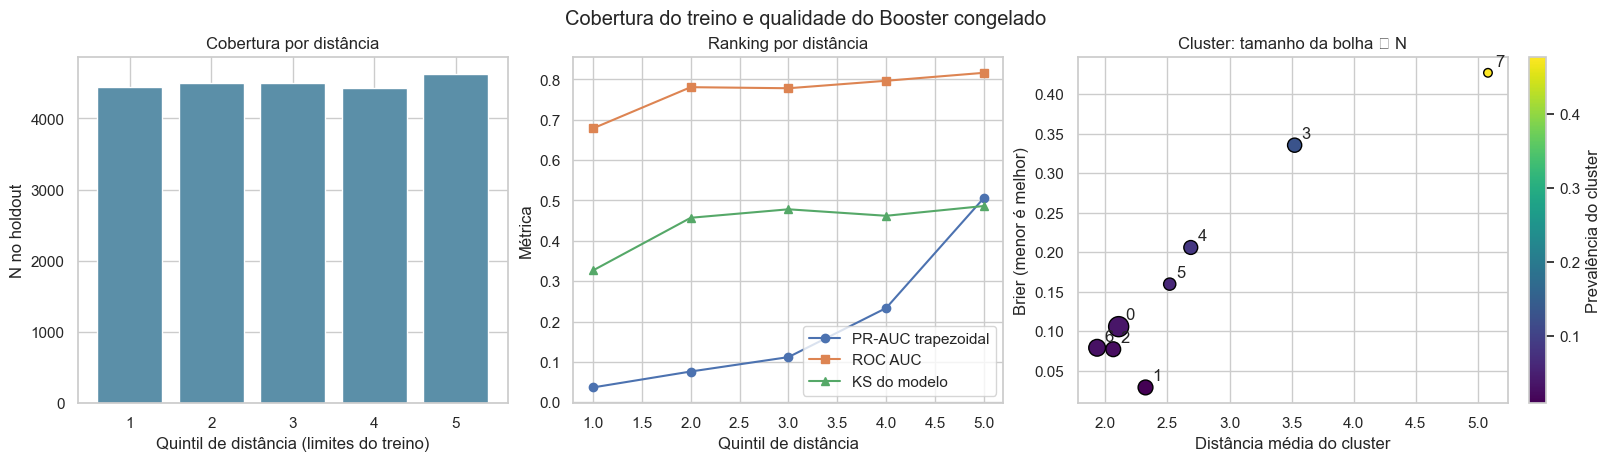

In [5]:
linhas_cluster = []
for k in range(K):
    sel = cluster_h == k
    m = metricas(y[sel], p0[sel]) if np.unique(y[sel]).size == 2 else {}
    linhas_cluster.append({"cluster": k, "n": int(sel.sum()), "positivos": int(y[sel].sum()),
                           "distancia_media": dist_h[sel].mean(), **m})
clusters = pd.DataFrame(linhas_cluster).sort_values("cluster")
clusters.to_csv(SAIDA / "13_clusters_holdout.csv", index=False)

arestas_dist = np.r_[-np.inf, np.unique(np.quantile(dist_t, [.2,.4,.6,.8])), np.inf]
grupo_dist = np.searchsorted(arestas_dist, dist_h, side="right") - 1
linhas_dist = []
for g in range(len(arestas_dist)-1):
    sel = grupo_dist == g
    m = metricas(y[sel], p0[sel]) if np.unique(y[sel]).size == 2 else {}
    linhas_dist.append({"quintil_treino": g+1, "n": int(sel.sum()), "positivos": int(y[sel].sum()),
                        "distancia_media": dist_h[sel].mean(), **m})
quintis = pd.DataFrame(linhas_dist)
quintis.to_csv(SAIDA / "13_quintis_distancia.csv", index=False)
display(clusters[["cluster", "n", "positivos", "distancia_media", "prevalencia", "auc_roc", "pr_auc_trap", "ks_modelo", "brier", "ap", "recall", "precision"]].round(4))
display(quintis[["quintil_treino", "n", "positivos", "distancia_media", "prevalencia", "auc_roc", "pr_auc_trap", "ks_modelo", "brier", "ap", "recall", "precision"]].round(4))

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
eixos[0].bar(quintis["quintil_treino"], quintis["n"], color="#5b8fa8")
eixos[0].set(xlabel="Quintil de distância (limites do treino)", ylabel="N no holdout", title="Cobertura por distância")
eixos[1].plot(quintis["quintil_treino"], quintis["pr_auc_trap"], marker="o", label="PR-AUC trapezoidal")
eixos[1].plot(quintis["quintil_treino"], quintis["auc_roc"], marker="s", label="ROC AUC")
eixos[1].plot(quintis["quintil_treino"], quintis["ks_modelo"], marker="^", label="KS do modelo")
eixos[1].set(xlabel="Quintil de distância", ylabel="Métrica", title="Ranking por distância")
eixos[1].legend()
bolhas = eixos[2].scatter(clusters["distancia_media"], clusters["brier"], s=clusters["n"]/25,
                         c=clusters["prevalencia"], cmap="viridis", edgecolor="black")
fig.colorbar(bolhas, ax=eixos[2], label="Prevalência do cluster")
for _, r in clusters.iterrows():
    eixos[2].annotate(str(int(r["cluster"])), (r["distancia_media"], r["brier"]), xytext=(5,5), textcoords="offset points")
eixos[2].set(xlabel="Distância média do cluster", ylabel="Brier (menor é melhor)", title="Cluster: tamanho da bolha ∝ N")
fig.suptitle("Cobertura do treino e qualidade do Booster congelado")
fig.savefig(FIGURES_DIR / '13_cobertura_segmentos.png', dpi=170, bbox_inches="tight")
plt.show()

## 13.5 Aumentar gradualmente o mix de perfis distantes

Seja `u_i` o percentil da distância `d_i` na distribuição de **treino**: `u_i = F_treino(d_i)`, de 0 a 1. Definimos `w_i(λ) = exp(λ u_i)`, com `λ` variando de 0 a 8. `λ=0` mantém pesos iguais; valores maiores aumentam a participação dos perfis distantes. O mesmo registro inteiro mantém seu rótulo e todas as relações entre entradas. `λ` é **intensidade do estressor**, não valor de PSI. Medimos o PSI resultante da distância, score e das dez marginais. Para pesos extremos, ESS cai e as estimativas ficam mais incertas; não extrapole além do suporte observado.

**Legenda:** `fração_distante` é a massa ponderada acima do p95 da distância do treino; `PSI_max_entrada` é o maior PSI entre as dez variáveis; `PSI_distância` mede a distribuição de `d_i`; `delta_pr_auc_trap` compara com o holdout sem reponderação. Usar uma única variável de maior PSI não captura por si só a mudança conjunta, então reportamos também distância e mix por cluster. Como a prevalência muda nessa mistura, uma PR-AUC crescente não significa necessariamente melhora em AUC, KS ou Brier: examine as quatro métricas e a prevalência.


,lambda,fracao_distante,ess_frac,psi_distancia,psi_cluster,psi_max_entrada,feature_psi_max,psi_score,prevalencia,auc_roc,pr_auc_trap,ks_modelo,brier,ap,recall,precision
0,0.0,0.0524,1.0000,0.0000,0.0000,0.0000,RevolvingUtilizationOfUnsecuredLines,0.0000,0.0667,0.8668,0.3960,0.5877,0.1440,0.3964,0.7940,0.2153
1,0.5,0.0656,0.9796,0.0206,0.0057,0.0052,RevolvingUtilizationOfUnsecuredLines,0.0068,0.0760,0.8689,0.4142,0.5908,0.1571,0.4146,0.8227,0.2250
2,1.0,0.0805,0.9240,0.0815,0.0226,0.0202,RevolvingUtilizationOfUnsecuredLines,0.0270,0.0860,0.8692,0.4297,0.5890,0.1706,0.4301,0.8469,0.2342
3,2.0,0.1144,0.7614,0.3108,0.0850,0.0742,RevolvingUtilizationOfUnsecuredLines,0.1045,0.1072,0.8656,0.4534,0.5762,0.1979,0.4539,0.8841,0.2506
4,3.0,0.1518,0.6039,0.6512,0.1738,0.1474,RevolvingUtilizationOfUnsecuredLines,0.2207,0.1285,0.8582,0.4700,0.5580,0.2238,0.4705,0.9099,0.2645
5,4.0,0.1906,0.4834,1.0625,0.2745,0.2256,RevolvingUtilizationOfUnsecuredLines,0.3607,0.1488,0.8489,0.4816,0.5435,0.2471,0.4821,0.9279,0.2764
6,6.0,0.2665,0.3345,1.9835,0.4722,0.3644,RevolvingUtilizationOfUnsecuredLines,0.6662,0.1844,0.8293,0.4960,0.5130,0.2849,0.4966,0.9500,0.2950
7,8.0,0.3365,0.2535,2.9431,0.6399,0.4658,RevolvingUtilizationOfUnsecuredLines,0.9671,0.2132,0.8108,0.5041,0.4844,0.3128,0.5047,0.9622,0.3089


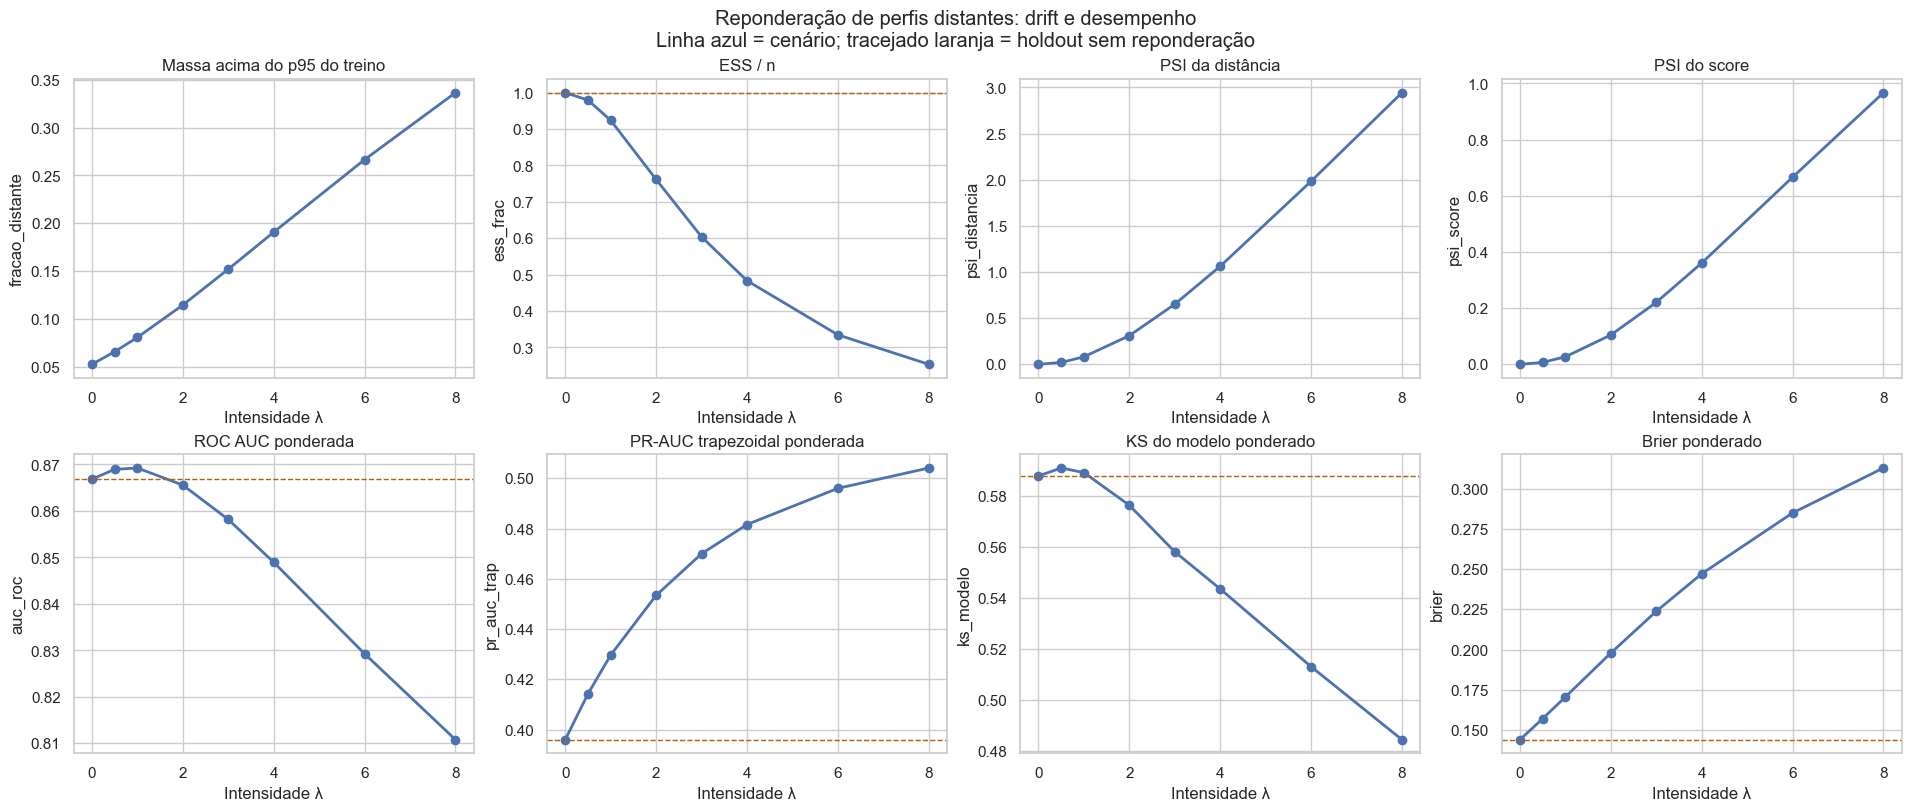

In [6]:
ordem_treino = np.sort(dist_t)
percentil_h = np.searchsorted(ordem_treino, dist_h, side="right") / len(ordem_treino)
arestas_score = bins_referencia(p0)
arestas_dist_psi = bins_referencia(dist_h)
arestas_entrada = {c: bins_referencia(Xh[c]) for c in FEATURES}

def psi_categorico(ref_cod, cod, pesos, n_cat):
    r = np.bincount(ref_cod, minlength=n_cat).astype(float)
    q = np.bincount(cod, weights=pesos, minlength=n_cat).astype(float)
    r /= r.sum(); q /= q.sum()
    eps = 1e-6
    return float(np.sum((q-r) * np.log((q+eps)/(r+eps))))

reponderados = []
for lam in [0, .5, 1, 2, 3, 4, 6, 8]:
    w = np.exp(lam * (percentil_h - percentil_h.max()))  # escala comum sem alterar proporções
    m = metricas(y, p0, w)
    psis_in = {c: psi(Xh[c], Xh[c], arestas_entrada[c], w) for c in FEATURES}
    reponderados.append({
        "lambda": lam, "fracao_distante": np.average(dist_h > limite95, weights=w),
        "distancia_media": np.average(dist_h, weights=w),
        "psi_distancia": psi(dist_h, dist_h, arestas_dist_psi, w),
        "psi_score": psi(p0, p0, arestas_score, w),
        "psi_cluster": psi_categorico(cluster_h, cluster_h, w, K),
        "psi_max_entrada": max(psis_in.values()),
        "feature_psi_max": max(psis_in, key=psis_in.get),
        "delta_ap": m["ap"] - base["ap"],
        "delta_auc_roc": m["auc_roc"] - base["auc_roc"],
        "delta_pr_auc_trap": m["pr_auc_trap"] - base["pr_auc_trap"],
        "delta_ks_modelo": m["ks_modelo"] - base["ks_modelo"],
        "delta_brier": m["brier"] - base["brier"],
        "delta_recall": m["recall"] - base["recall"],
        "delta_fpr": m["fpr"] - base["fpr"],
        **m,
    })
mistura = pd.DataFrame(reponderados)
assert np.isclose(mistura.iloc[0]["psi_distancia"], 0) and np.isclose(mistura.iloc[0]["ap"], base["ap"])
mistura.to_csv(SAIDA / "13_mix_distante.csv", index=False)
display(mistura[["lambda", "fracao_distante", "ess_frac", "psi_distancia", "psi_cluster",
                 "psi_max_entrada", "feature_psi_max", "psi_score", "prevalencia", "auc_roc", "pr_auc_trap", "ks_modelo", "brier", "ap", "recall", "precision"]].round(4))

fig, eixos = plt.subplots(2, 4, figsize=(19, 8), constrained_layout=True)
for ax, (c, t) in zip(eixos.flat,
    [("fracao_distante", "Massa acima do p95 do treino"), ("ess_frac", "ESS / n"),
     ("psi_distancia", "PSI da distância"), ("psi_score", "PSI do score"),
     ("auc_roc", "ROC AUC ponderada"), ("pr_auc_trap", "PR-AUC trapezoidal ponderada"),
     ("ks_modelo", "KS do modelo ponderado"), ("brier", "Brier ponderado")]):
    ax.plot(mistura["lambda"], mistura[c], marker="o", lw=2)
    if c in base:
        ax.axhline(base[c], ls="--", color="#b45f06", lw=1)
    ax.set(xlabel="Intensidade λ", ylabel=c, title=t)
fig.suptitle("Reponderação de perfis distantes: drift e desempenho\n"
             "Linha azul = cenário; tracejado laranja = holdout sem reponderação")
fig.savefig(FIGURES_DIR / '13_mix_distante_evolucao.png', dpi=170, bbox_inches="tight")
plt.show()

## 13.6 Janelas pequenas: variabilidade sem drift real

Inspirada pela pergunta do `thinning`, esta adaptação sorteia **janelas de monitoramento** de tamanhos `n=250` até `10.000`, sem reposição, repetindo 100 vezes por tamanho. Nenhum modelo é retreinado. Todas as janelas vêm do **mesmo** holdout; logo, diferenças de AUC, PR-AUC, KS, Brier, recall ou PSI em relação à referência são **ruído amostral**, não um drift deliberado. Uma distribuição empírica de PSI por tamanho de janela evita chamar qualquer valor positivo de incidente. A comparação ainda subestima mudanças reais futuras e usa o mesmo conjunto para referência e sorteio; uma validação temporal futura é necessária.

`q05`, `mediana` e `q95` são percentis sobre as 100 repetições, **não** intervalos de confiança para produção. O número de positivos em uma janela é mostrado porque AP varia com prevalência e tamanho. O PSI da janela usa bins e proporções da referência completa. Nenhum rótulo é gerado aleatoriamente; todos são os valores verdadeiros do CSV rotulado.


,n_janela,positivos_mediana,psi_score_mediana,psi_score_q95,auc_q05,auc_mediana,auc_q95,pr_auc_q05,pr_auc_mediana,pr_auc_q95,ks_q05,ks_mediana,ks_q95,brier_q05,brier_mediana,brier_q95,recall_q05,recall_mediana,recall_q95,precision_mediana
0,250,17.0,0.0301,0.0653,0.7788,0.8713,0.9334,0.2413,0.4105,0.6163,0.5091,0.6365,0.7906,0.1243,0.1450,0.1647,0.6146,0.7857,0.9474,0.2126
1,500,32.5,0.0172,0.0347,0.7887,0.8707,0.9116,0.2454,0.3957,0.5476,0.5027,0.6186,0.7181,0.1285,0.1444,0.1630,0.6667,0.7795,0.8966,0.2112
2,1000,66.5,0.0080,0.0153,0.8389,0.8723,0.9024,0.3088,0.4131,0.4917,0.5504,0.6276,0.6819,0.1328,0.1420,0.1557,0.7418,0.8048,0.8717,0.2179
3,2500,168.0,0.0033,0.0064,0.8409,0.8629,0.8857,0.3362,0.3944,0.4615,0.5487,0.5919,0.6371,0.1370,0.1433,0.1510,0.7396,0.7898,0.8319,0.2164
4,5000,333.0,0.0014,0.0025,0.8543,0.8682,0.8814,0.3585,0.4000,0.4350,0.5682,0.5948,0.6229,0.1401,0.1440,0.1483,0.7718,0.7954,0.8225,0.2149
5,10000,668.0,0.0004,0.0010,0.8589,0.8672,0.8773,0.3678,0.3979,0.4188,0.5762,0.5912,0.6138,0.1410,0.1439,0.1464,0.7796,0.7949,0.8159,0.2152


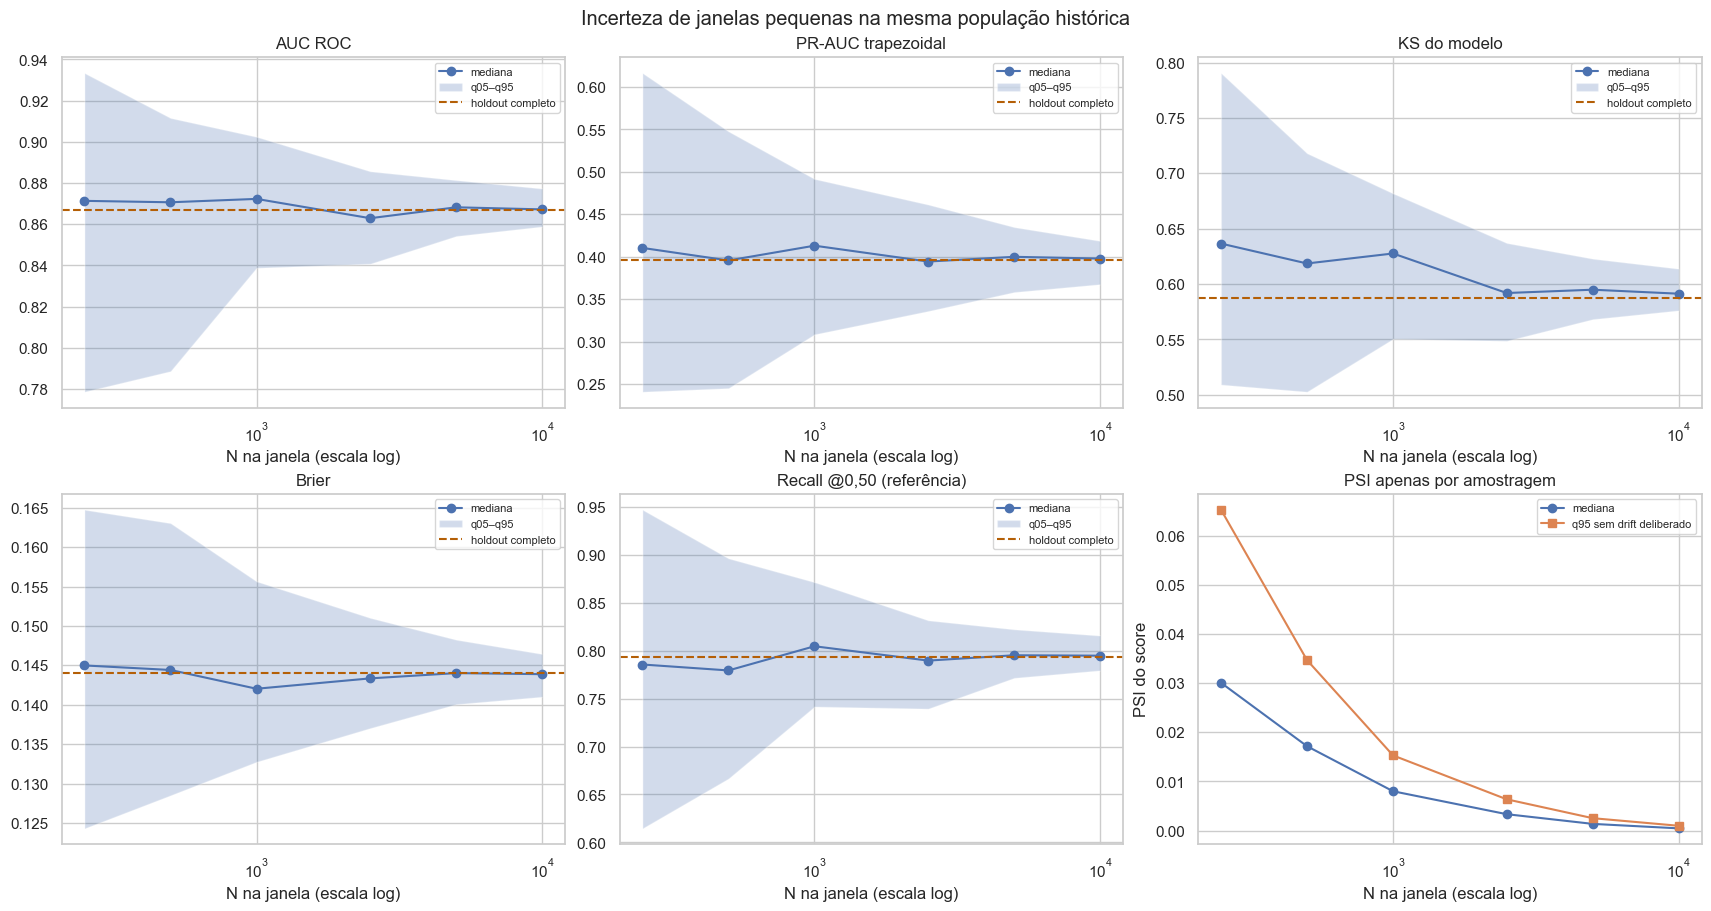

In [7]:
rng = np.random.default_rng(SEMENTE + 1300)
janelas = []
for n in [250, 500, 1000, 2500, 5000, 10000]:
    for repeticao in range(100):
        idx = rng.choice(len(y), n, replace=False)
        if len(np.unique(y[idx])) < 2:
            continue
        m = metricas(y[idx], p0[idx])
        janelas.append({"n_janela": n, "repeticao": repeticao,
                        "positivos": int(y[idx].sum()),
                        "psi_score": psi(p0, p0[idx], arestas_score),
                        **m})
janelas = pd.DataFrame(janelas)
janelas.to_csv(SAIDA / "13_janelas_repeticoes.csv", index=False)
resumo_janelas = janelas.groupby("n_janela").agg(
    positivos_mediana=("positivos", "median"),
    psi_score_mediana=("psi_score", "median"), psi_score_q95=("psi_score", lambda x: x.quantile(.95)),
    auc_q05=("auc_roc", lambda x: x.quantile(.05)), auc_mediana=("auc_roc", "median"),
    auc_q95=("auc_roc", lambda x: x.quantile(.95)),
    pr_auc_q05=("pr_auc_trap", lambda x: x.quantile(.05)), pr_auc_mediana=("pr_auc_trap", "median"),
    pr_auc_q95=("pr_auc_trap", lambda x: x.quantile(.95)),
    ks_q05=("ks_modelo", lambda x: x.quantile(.05)), ks_mediana=("ks_modelo", "median"),
    ks_q95=("ks_modelo", lambda x: x.quantile(.95)),
    brier_q05=("brier", lambda x: x.quantile(.05)), brier_mediana=("brier", "median"),
    brier_q95=("brier", lambda x: x.quantile(.95)),
    recall_q05=("recall", lambda x: x.quantile(.05)), recall_mediana=("recall", "median"),
    recall_q95=("recall", lambda x: x.quantile(.95)),
    precision_mediana=("precision", "median"),
).reset_index()
resumo_janelas.to_csv(SAIDA / "13_janelas_resumo.csv", index=False)
display(resumo_janelas.round(4))

fig, eixos = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)
xx = resumo_janelas["n_janela"].to_numpy()
for ax, media, q05, q95, referencia, titulo in [
    (eixos[0,0], "auc_mediana", "auc_q05", "auc_q95", base["auc_roc"], "AUC ROC"),
    (eixos[0,1], "pr_auc_mediana", "pr_auc_q05", "pr_auc_q95", base["pr_auc_trap"], "PR-AUC trapezoidal"),
    (eixos[0,2], "ks_mediana", "ks_q05", "ks_q95", base["ks_modelo"], "KS do modelo"),
    (eixos[1,0], "brier_mediana", "brier_q05", "brier_q95", base["brier"], "Brier"),
    (eixos[1,1], "recall_mediana", "recall_q05", "recall_q95", base["recall"], "Recall @0,50 (referência)")]:
    ax.plot(xx, resumo_janelas[media], marker="o", label="mediana")
    ax.fill_between(xx, resumo_janelas[q05].to_numpy(), resumo_janelas[q95].to_numpy(), alpha=.25, label="q05–q95")
    ax.axhline(referencia, ls="--", color="#b45f06", label="holdout completo")
    ax.set_xscale("log")
    ax.set(xlabel="N na janela (escala log)", title=titulo)
    ax.legend(fontsize=8)
eixos[1,2].plot(xx, resumo_janelas["psi_score_mediana"], marker="o", label="mediana")
eixos[1,2].plot(xx, resumo_janelas["psi_score_q95"], marker="s", label="q95 sem drift deliberado")
eixos[1,2].set_xscale("log")
eixos[1,2].set(xlabel="N na janela (escala log)", ylabel="PSI do score", title="PSI apenas por amostragem")
eixos[1,2].legend(fontsize=8)
fig.suptitle("Incerteza de janelas pequenas na mesma população histórica")
fig.savefig(FIGURES_DIR / '13_janelas_incerteza.png', dpi=170, bbox_inches="tight")
plt.show()

## 13.7 Conclusões, limites e reprodução

Compare `λ`, `ESS/n`, PSI da distância e as quatro métricas para identificar regiões em que a mistura de perfis afetou o Booster **neste holdout**. Neste experimento, a prevalência pode crescer ao enfatizar a cauda distante: portanto, PR-AUC ou AP bruta podem subir enquanto AUC, KS e Brier pioram. Uma queda por cluster não prova que a distância a causou; clusters também podem ter prevalências distintas. A distribuição de janelas mostra quanto PSI pode oscilar apenas por amostragem. Não definimos parada nem alerta nesta análise; uma eventual política exigiria validação temporal e revisão do contexto.

**Como replicar em outra aplicação:**

1. Preserve treino, validação e holdout rotulado, com datas quando disponíveis; congele o modelo final e seus scores de referência.
2. Escolha uma representação de distância com as escalas e ausências próprias do domínio. Ajuste medianas, transformação, centros de cluster e quantis de distância **somente no treino**; documente `K` e os quantis.
3. Atribua cada linha do holdout a um cluster e faixa de distância. Conte `n`, positivos e prevalência antes de comparar métricas, pois grupos pequenos geram curvas instáveis.
4. Defina uma sequência de pesos `w_i(λ)` para dar mais massa aos perfis distantes, mantendo cada linha inteira e seu rótulo verdadeiro. Para cada `λ`, registre massa deslocada, PSI de distância/marginais/score e `ESS/n`.
5. Calcule AUC ROC, PR-AUC trapezoidal, KS do modelo e Brier com os mesmos pesos, além de recall e precisão descritivos; examine toda a curva, sem valor de parada.
6. Sorteie janelas de vários tamanhos do holdout sem estresse para estimar a oscilação amostral de PSI e métricas; isso não simula uma nova safra de risco.
7. Investigue casos realmente fora do suporte em dados futuros e reavalie com rótulos maturados. Se quiser o `cv_cluster` ou `thinning` originais, treine **modelos auxiliares** por repetição, separados da avaliação do Booster final. Use o mesmo `scale_pos_weight=13.882494684620836` se desejar comparação com esta versão.

**Referência metodológica:** manual local `stressor.pdf`, entradas `cv_cluster`, `dist_cent` e `thinning`. As implementações deste notebook são adaptações explícitas em Python, não chamadas equivalentes à biblioteca R.
